# Card prediction — v3 pipeline

**What is served.** One model for the big five leagues: a **five-league ensemble** of
bagged boosters, a logistic and a team-count decomposition (§19). Everything that scores a
fixture — `serve/predict.py`, `serve/todays_slate.py`, `serve/card_market.py`,
`serve/player_confidence.py` — uses it.

**How this notebook is ordered.** §1–§17 are how the model was built and tested, on the
Premier League archive where the project started: the label, the leakage-free feature
store, the booster, and every experiment that did or did not make it in. §18 extends the
same pipeline to Serie A, La Liga, the Bundesliga and Ligue 1, and §19 is the ensemble
that ships. The Premier-League-only model trained in §5 is kept as the research baseline.

**Question.** Given the confirmed team sheets about an hour before kick-off, which
starters are most likely to **be booked**?

**Population.** The 20 outfield players in the two starting XIs (goalkeepers excluded —
they are booked about a tenth as often and are never the pick on a shortlist).

**Label — the part that matters.** The market resolves a named starter as a
*win* if that player **or whoever replaces him** is booked. So `y_card = 1` when
anyone occupying that starter's shirt-slot sees a yellow or a straight red, not just
the named player. Section 2 recovers the substitution chains and shows what the
difference is worth — about one hit in ten.

FBref's `CrdY` already counts the first booking of a second-yellow dismissal, which
this notebook verifies rather than assumes.

**Objective.** Calibrated probabilities first (a predicted 0.22 should mean 22%), with
per-match top-K precision as the practical read.

---

### How this differs from v2

| | v2 | v3 |
|---|---|---|
| Model dataset | 273 MB, 462 features | **5 MB, 28 features** |
| Label | the named player only | **the player or his substitute** — what the market resolves on |
| Match context | none | live table, Elo, fixture difficulty, stakes (`context.py`) |
| Starter flag | wrong for every away player | exact (22/match, verified) |
| Feature alignment | rolling stats joined back on a reset index, so rows were shuffled against their own history | single as-of join, verified by rebuilding from a truncated history |
| Minutes played | used as a feature | excluded — it is only known after the match |
| Split | random `train_test_split` | chronological, plus 4-season walk-forward |
| Class imbalance | `scale_pos_weight` | untouched (it destroys calibration and does not change ranking) |

Run order: `pipeline/build_base_table.py` → `pipeline/features.py` → this notebook.
The five-league build and the ensemble: `pipeline/pooled.py build --first-season 2017-2018`
→ `pipeline/ensemble.py all`.

In [1]:
import sys, warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

V3_DIR = Path.cwd()
while not (V3_DIR / "paths.py").exists() and V3_DIR != V3_DIR.parent:   # from notebooks/
    V3_DIR = V3_DIR.parent
sys.path.insert(0, str(V3_DIR))
import paths  # noqa: F401 - puts pipeline/, serve/, research/ on sys.path

import config, build_base_table, features, modelling, evaluation, predict, pooled, ensemble

warnings.filterwarnings("ignore")
pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 60)
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": .3,
                     "axes.spines.top": False, "axes.spines.right": False})

REBUILD = False   # True re-parses all 3,040 match folders (~3 min)
print("working dir:", V3_DIR)

working dir: <repo>


---
## 1. Stage 1 — raw match folders → tidy base tables

Each of the 3,040 match folders holds six CSVs. `build_base_table.py` reads the
line-up sheet **per side** (the v2 loader searched for the `Bench` separator on the
concatenated frame, which silently marked every away starter as a substitute) and uses
that sheet as the spine, so unused substitutes survive with `appeared = False`.

In [2]:
if REBUILD or not config.BASE_TABLE_PATH.exists():
    players, teams = build_base_table.build()
    config.BASE_TABLE_PATH.parent.mkdir(parents=True, exist_ok=True)
    players.to_parquet(config.BASE_TABLE_PATH, index=False)
    teams.to_parquet(config.MATCH_TABLE_PATH, index=False)
else:
    players = pd.read_parquet(config.BASE_TABLE_PATH)
    teams = pd.read_parquet(config.MATCH_TABLE_PATH)

print(f"{players['match_id'].nunique():,} matches | {len(players):,} player-match rows "
      f"| {len(teams):,} team-match rows")
players.head(3)[["player", "team", "side", "is_starter", "appeared", "minutes",
                 "fouls", "yellow", "red", "referee", "kickoff"]]

3,470 matches | 133,935 player-match rows | 6,940 team-match rows


,player,team,side,is_starter,appeared,minutes,fouls,yellow,red,referee,kickoff
0,Kasper Schmeichel,Leicester City,away,True,True,90.0,0.0,0.0,0.0,Mike Dean,2017-08-11 19:45:00
1,Danny Simpson,Leicester City,away,True,True,90.0,0.0,0.0,0.0,Mike Dean,2017-08-11 19:45:00
2,Wes Morgan,Leicester City,away,True,True,90.0,4.0,1.0,0.0,Mike Dean,2017-08-11 19:45:00


### Sanity checks on the parse

These are the numbers that were wrong in v2, so they are printed rather than trusted.

In [3]:
starters = players[players["is_starter"]]
print(f"starters per match : {len(starters) / players['match_id'].nunique():.2f}  (expect 22.00)")
print(f"every starter appeared: {starters['appeared'].all()}")
print(f"unused substitutes    : {(~players['appeared']).sum():,}")

# Does CrdY already include the first booking of a second-yellow dismissal?
xt = pd.crosstab(players["yellow"], players["second_yellow"])
print("\nyellow x second_yellow:")
print(xt)
print("\n-> every CrdY == 2 row is a second-yellow dismissal, so `yellow >= 1`")
print("   captures second bookings and no separate handling is needed.")

starters per match : 22.00  (expect 22.00)
every starter appeared: True
unused substitutes    : 34,189

yellow x second_yellow:
second_yellow     0.0  1.0
yellow                    
0.0            106028    0
1.0             10560    0
2.0                 0  158

-> every CrdY == 2 row is a second-yellow dismissal, so `yellow >= 1`
   captures second bookings and no separate handling is needed.


---
## 2. The label: player **or his substitute**

FBref publishes no "X replaced Y" field. But it prints each team's player table in
*slot* order — a starter, then whoever replaced him, then whoever replaced that
replacement. Anchoring the slot boundaries on the line-up sheet's **starters**, rather
than on minutes adding up to 90, stays exact even when a sending-off leaves a slot short.

A naive "accumulate minutes until 90" rule gets this right 94.2% of the time and fails on
exactly the team-matches containing a red card. The rule below was checked on all 6,080
team-tables before anything was built on it.

In [4]:
appeared = players[players["slot_id"].notna()]
per_side = appeared.groupby(["match_id", "side"])["slot_id"].nunique()
print(f"team-tables            : {len(per_side):,}")
print(f"with exactly 11 slots  : {(per_side == 11).sum():,}  ({(per_side == 11).mean():.2%})")

slot_min = appeared.groupby("slot_id")["minutes"].sum()
print(f"slots longer than 90'  : {(slot_min > 90).sum()}   <- must be zero")
print(f"slots exactly 90'      : {(slot_min == 90).sum():,}")
print(f"slots under 90'        : {(slot_min < 90).sum():,}  (red card, or finished with ten)")
print()
print("players per slot:",
      appeared.groupby("slot_id").size().value_counts().sort_index().to_dict())

team-tables            : 6,940
with exactly 11 slots  : 6,940  (100.00%)
slots longer than 90'  : 0   <- must be zero
slots exactly 90'      : 75,923
slots under 90'        : 417  (red card, or finished with ten)

players per slot: {1: 53069, 2: 23137, 3: 133, 4: 1}


Now what the label is worth. The two labels differ only by the replacement leg, but that
leg decides a meaningful share of hits — and its share is **growing**, which is
the five-substitution rule working through the data.

In [5]:
out_st = players[players["is_starter"] & (players["pos_group_actual"] != "GK")]
print(f"{'named player carded':<34}{out_st['y_any_card'].mean():.4f}")
print(f"{'player OR his replacement carded':<34}{out_st['y_slot_any_card'].mean():.4f}")
print(f"{'starter replaced at all':<34}{out_st['was_replaced'].mean():.4f}")
print(f"{'hit won by the substitute alone':<34}{out_st['repl_card'].mean():.4f}")
share = out_st["repl_card"].sum() / out_st["y_slot_any_card"].sum()
print(f"\n-> {share:.1%} of hits are won by the substitute, not the named player")

fig, axes = plt.subplots(1, 2, figsize=(11, 3.6))
by_s = out_st.groupby("season")[["y_any_card", "y_slot_any_card"]].mean()
x = range(len(by_s))
labels = [s[2:4] + "/" + s[-2:] for s in by_s.index]
axes[0].plot(x, by_s["y_any_card"], "o-", color="#c0563f", label="named player only")
axes[0].plot(x, by_s["y_slot_any_card"], "o-", color="#3b6ea5", label="player or his sub")
axes[0].set_xticks(list(x)); axes[0].set_xticklabels(labels, fontsize=8)
axes[0].set_title("the two labels, by season"); axes[0].legend(fontsize=8)
axes[0].set_ylabel("P(win)")

gap = out_st.groupby("season")["repl_card"].mean()
axes[1].bar(range(len(gap)), gap.to_numpy(), color="#6b8f3a")
axes[1].set_xticks(range(len(gap))); axes[1].set_xticklabels(labels, fontsize=8)
axes[1].set_title("hits won by the substitute alone")
axes[1].axvline(4.5, ls="--", c="grey", lw=1)
axes[1].text(4.6, gap.max() * 0.85, "5 subs\npermanent", fontsize=7, color="grey")
plt.tight_layout(); plt.show()

named player carded               0.1550
player OR his replacement carded  0.1726
starter replaced at all           0.3344
hit won by the substitute alone   0.0177

-> 10.2% of hits are won by the substitute, not the named player


### One chain, spelled out

A single team in a single match. Seat 0 is the starter, seat 1 whoever came on for him.
A pick on the seat-0 player resolves on the whole slot — so the last column is the same for
every row of a slot.

In [6]:
eg_id = players["match_id"].iloc[-40]
eg = players[(players["match_id"] == eg_id) & (players["side"] == "home")
             & players["slot_id"].notna()].sort_values(["slot_id", "slot_seat"])
print(eg_id, "\n")
print(eg.assign(slot=lambda d: d.slot_id.str.split("|").str[-1])
        [["slot", "slot_seat", "player", "minutes", "yellow", "red", "y_slot_any_card"]]
        .to_string(index=False))

2026-2027|05|Fulham|Manchester Utd 

slot  slot_seat            player  minutes  yellow  red  y_slot_any_card
  00        0.0    Gonzalo García     79.0     0.0  0.0                1
  00        1.0     Rodrigo Muniz     11.0     1.0  0.0                1
  01        0.0        Alex Iwobi     70.0     0.0  0.0                0
  01        1.0    César Palacios     20.0     0.0  0.0                0
  02        0.0       Joshua King     79.0     1.0  0.0                1
  02        1.0  Joachim Andersen     11.0     0.0  0.0                1
  03        0.0        Oscar Bobb     70.0     0.0  0.0                0
  03        1.0             Kevin     20.0     0.0  0.0                0
  04        0.0      Shea Charles     90.0     0.0  0.0                0
  05        0.0      Sander Berge     76.0     0.0  0.0                0
  05        1.0      Hugo Larsson     14.0     0.0  0.0                0
  06        0.0  Antonee Robinson     90.0     0.0  0.0                0
  07        0.

---
## 2b. What the label looks like across the league

Three things worth knowing before modelling: how often a slot wins, how much that rate
drifts between seasons, and how it varies by position.

win rate, outfield starter slots: 0.1726
cards per match (all players): 3.73


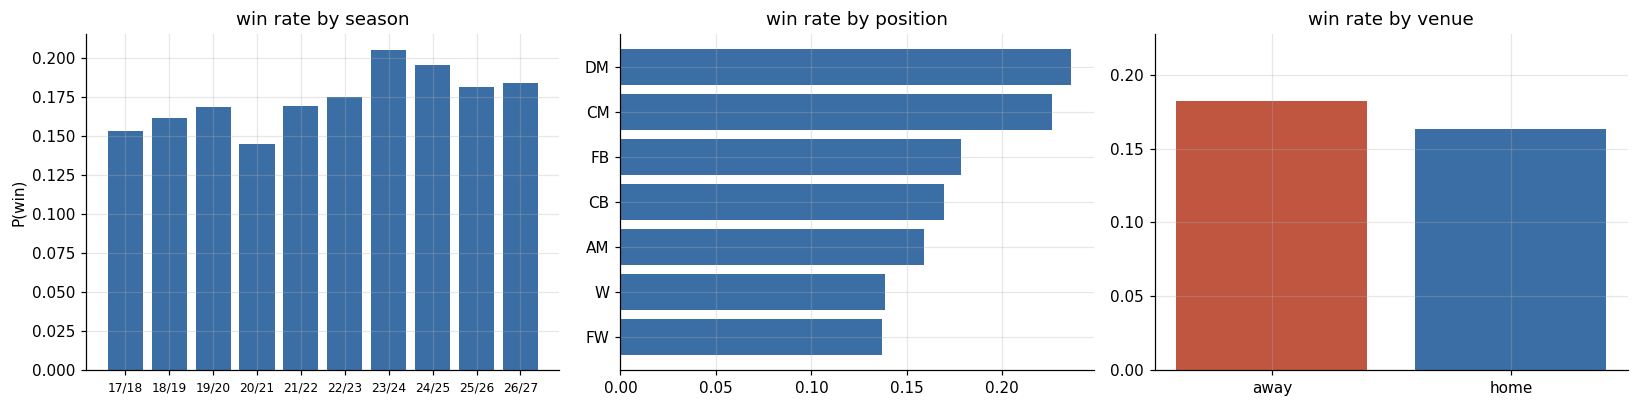


season drift: 0.145 -> 0.205 (+42% between the quietest and busiest season)


In [7]:
starters_out = players[players["is_starter"] & (players["pos_group_actual"] != "GK")]
print(f"win rate, outfield starter slots: {starters_out['y_slot_any_card'].mean():.4f}")
print(f"cards per match (all players): "
      f"{(players['yellow'] + players['red']).sum() / players['match_id'].nunique():.2f}")

fig, axes = plt.subplots(1, 3, figsize=(15, 3.8))

by_season = starters_out.groupby("season")["y_slot_any_card"].mean()
axes[0].bar(range(len(by_season)), by_season.to_numpy(), color="#3b6ea5")
axes[0].set_xticks(range(len(by_season)))
axes[0].set_xticklabels([s[2:4] + "/" + s[-2:] for s in by_season.index], fontsize=8)
axes[0].set_title("win rate by season")
axes[0].set_ylabel("P(win)")

by_pos = (starters_out.groupby("pos_group_actual")["y_slot_any_card"]
          .agg(["mean", "size"]).sort_values("mean"))
axes[1].barh(by_pos.index, by_pos["mean"].to_numpy(), color="#3b6ea5")
axes[1].set_title("win rate by position")

by_home = starters_out.groupby("is_home")["y_slot_any_card"].mean()
axes[2].bar(["away", "home"], by_home.to_numpy(), color=["#c0563f", "#3b6ea5"])
axes[2].set_title("win rate by venue")
axes[2].set_ylim(0, by_home.max() * 1.25)
plt.tight_layout(); plt.show()

print(f"\nseason drift: {by_season.min():.3f} -> {by_season.max():.3f} "
      f"(+{100 * (by_season.max() / by_season.min() - 1):.0f}% between the quietest and "
      "busiest season)")

Two facts that shape the design:

* **Positional spread is large** (defensive midfielders roughly double forwards), so
  position has to be in the model — but taken from *history*, not from the position the
  player ended up covering in the match being predicted.
* **The league-wide rate drifts upward across seasons.** That is why a calibrator fitted
  on one season transfers badly, which is measured in section 6 rather than assumed.

---
## 3. Stage 2 — the feature store

One rule, applied everywhere: *a feature for match M may only use matches that kicked
off strictly before M*.

It is implemented once, as an as-of join:

```python
pd.merge_asof(candidates, entity_state, on="kickoff", by=entity,
              direction="backward", allow_exact_matches=False)
```

`entity_state` holds each player's / team's / referee's cumulative and rolling totals
*after* each of their matches. The backward, non-exact join therefore attaches
"everything known up to their previous match" — no `shift` juggling, and no
`reset_index(drop=True)`, which is what silently misaligned rows against their own
history in v2.

Thin histories are shrunk towards a league prior (empirical Bayes), so a player with two
appearances is not credited with a 0.00 or 9.00 fouls-per-90 rate. The priors are
estimated on the training seasons only.

In [8]:
if REBUILD or not config.MODEL_DATASET_PATH.exists():
    dataset, priors = features.build_model_dataset(players, teams)
    dataset.to_parquet(config.MODEL_DATASET_PATH, index=False)
else:
    dataset = pd.read_parquet(config.MODEL_DATASET_PATH)

size_mb = config.MODEL_DATASET_PATH.stat().st_size / 1e6
print(f"{len(dataset):,} rows x {len(config.FEATURES)} features  ({size_mb:.1f} MB on disk)")
print(f"base rate: {dataset[config.TARGET_COL].mean():.4f}")
dataset.head(3)[["player", "team", "pos_group", "plr_cards_p90_eb", "plr_fouls_p90_eb",
                 "ref_cards_pm_eb", "exp_cards_analytic", config.TARGET_COL]]

69,400 rows x 32 features  (9.4 MB on disk)
base rate: 0.1726


,player,team,pos_group,plr_cards_p90_eb,plr_fouls_p90_eb,ref_cards_pm_eb,exp_cards_analytic,y_card
0,Alex Oxlade-Chamberlain,Arsenal,UNK,0.168322,0.969965,7.392763,0.149619,0
1,Alexandre Lacazette,Arsenal,UNK,0.168322,0.969965,7.392763,0.149619,0
2,Danny Welbeck,Arsenal,UNK,0.168322,0.969965,7.392763,0.149619,0


### Match context

Beyond the player, the model sees what a human reads off the table before looking at any
team sheet: where both sides stand, how hard the fixture is, what is still at stake, and
how ill-tempered this particular pairing tends to be. All of it is built in
`context.py` under the same as-of rule, and shared with the match-result model.

**Difficulty** is defined concretely rather than hand-waved: the opponent's Elo win
expectancy for this fixture, venue included. 0 means a certain win, 0.5 a coin toss,
1 hopeless. **Fixture history** is a data-driven stand-in for "is this a derby" — the
pairing's own card record says so without anyone curating a list of rivalries.

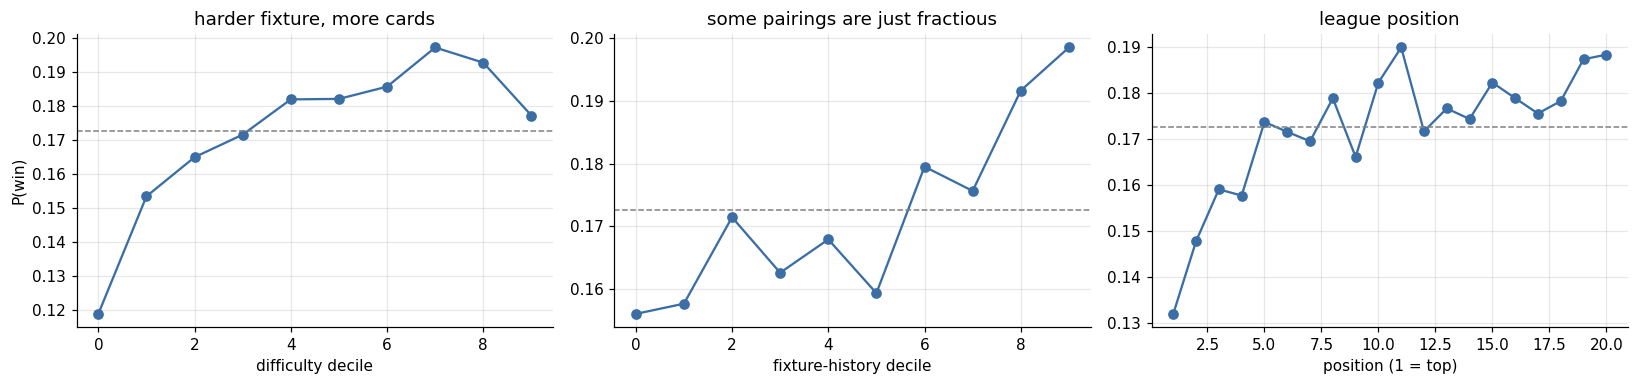

The dashed line is the overall base rate. Context moves the odds by roughly
a factor of 1.7 from the easiest fixtures to the hardest.


In [9]:
fig, axes = plt.subplots(1, 3, figsize=(15, 3.6))

d = dataset.copy()
for ax, col, title, xlabel in [
        (axes[0], "ctx_match_difficulty", "harder fixture, more cards", "difficulty decile"),
        (axes[1], "ctx_fixture_cards_pm_eb", "some pairings are just fractious", "fixture-history decile"),
        (axes[2], "ctx_position", "league position", "position (1 = top)")]:
    if col == "ctx_position":
        g = d.groupby(d[col].round())[config.TARGET_COL].mean()
        ax.plot(g.index, g.to_numpy(), "o-", color="#3b6ea5")
    else:
        d["_b"] = pd.qcut(d[col], 10, labels=False, duplicates="drop")
        g = d.groupby("_b")[config.TARGET_COL].mean()
        ax.plot(g.index, g.to_numpy(), "o-", color="#3b6ea5")
    ax.axhline(d[config.TARGET_COL].mean(), ls="--", c="grey", lw=1)
    ax.set_title(title); ax.set_xlabel(xlabel)
axes[0].set_ylabel("P(win)")
plt.tight_layout(); plt.show()

print("The dashed line is the overall base rate. Context moves the odds by roughly")
print("a factor of 1.7 from the easiest fixtures to the hardest.")

### The 28 features

In [10]:
groups = {
    "player discipline": [f for f in config.NUMERIC_FEATURES
                          if f.startswith("plr_") and "age" not in f
                          and "apps" not in f and "mins" not in f],
    "player exposure":   ["plr_apps_prior", "plr_mins_roll", "plr_age_years"],
    "fixture":           ["is_home", "matchweek"],
    "team / opponent":   [f for f in config.NUMERIC_FEATURES
                          if f.startswith(("team_", "opp_", "strength", "poss"))],
    "referee":           [f for f in config.NUMERIC_FEATURES if f.startswith("ref_")],
    "match context":     [f for f in config.NUMERIC_FEATURES if f.startswith("ctx_")],
    "composite":         ["exp_cards_analytic"],
    "categorical":       config.CATEGORICAL_FEATURES,
}
for name, cols in groups.items():
    print(f"{name:20s} ({len(cols)})  {', '.join(cols)}")
print(f"\nTOTAL {len(config.FEATURES)} features")

player discipline    (8)  plr_cards_p90_eb, plr_cards_p90_ewm, plr_fouls_p90_eb, plr_fouls_p90_ewm, plr_cards_pm_roll, plr_cards_per_foul_eb, plr_matches_since_card, plr_cards_season_to_date
player exposure      (3)  plr_apps_prior, plr_mins_roll, plr_age_years
fixture              (2)  is_home, matchweek
team / opponent      (4)  team_fouls_pm_roll, team_cards_pm_roll, opp_fouls_drawn_pm_roll, strength_diff
referee              (1)  ref_cards_pm_eb
match context        (7)  ctx_match_difficulty, ctx_fixture_cards_pm_eb, ctx_elo_diff, ctx_position, ctx_opp_position, ctx_stakes, ctx_matches_last_14d
composite            (1)  exp_cards_analytic
categorical          (2)  pos_group, formation

TOTAL 32 features


### Leakage gates

`tests/test_pipeline.py` rebuilds the entire feature table from a **truncated** history
and asserts every surviving row is bit-identical to the full build. If any feature had
peeked at a later match, truncating the future would move it and the check would fail.

In [11]:
import subprocess
res = subprocess.run([sys.executable, str(V3_DIR / "tests" / "test_pipeline.py")],
                     capture_output=True, text=True, cwd=str(V3_DIR))
print(res.stdout[-2600:])
if res.returncode != 0:
    print("STDERR:", res.stderr[-1500:])


base: 133,935 player rows, 6,940 team rows, dataset: 69,400 rows

--- base tables ---
[PASS] every match has exactly 22 starters  -- 3470 matches
[PASS] every match has exactly 2 teams
[PASS] no duplicated (match, player_key)  -- same-name players are split by club
[PASS] every starter appeared
[PASS] minutes are never negative or above 90
[PASS] CrdY==2 always coincides with a second yellow  (where published)  -- so yellow>=1 already captures second bookings; verified on 8 of 10 seasons, 158 second bookings
[PASS] the second-yellow column is either fully present or fully absent  -- a season missing it only sometimes would mean a parsing bug
[PASS] kickoff parsed for every row
[PASS] no club name is contained in another  -- 34 distinct clubs
[PASS] club count is consistent with promotion and relegation  -- 34 clubs over 10 seasons (ceiling 47)
[PASS] every season has exactly 20 clubs  -- 10 seasons

--- model dataset ---
[PASS] model dataset has 20 outfield starters per match  -- min=

---
## 4. Chronological split

Train on the past, validate on the next season, test on the most recent one. The first
season is burn-in: it only exists to warm up the rolling histories.

In [12]:
train, valid, test = modelling.split_dataset(dataset)
for name, part in [("burn-in", config.BURN_IN_SEASONS), ("train", config.TRAIN_SEASONS),
                   ("valid", config.VALID_SEASONS), ("test", config.TEST_SEASONS)]:
    rows = dataset[dataset["season"].isin(part)]
    if len(rows):
        print(f"{name:8s} {', '.join(part):45s} {len(rows):>7,} rows  "
              f"base rate {rows[config.TARGET_COL].mean():.4f}")

burn-in  2017-2018                                       7,600 rows  base rate 0.1528
train    2018-2019, 2019-2020, 2020-2021, 2021-2022, 2022-2023, 2023-2024, 2024-2025  53,200 rows  base rate 0.1740
valid    2025-2026                                       7,600 rows  base rate 0.1809
test     2026-2027                                       1,000 rows  base rate 0.1840


---
## 5. Train, and compare against baselines that actually matter

A model is only interesting if it beats the obvious alternatives, so it is scored against
three of them:

1. **base rate** — the league average, no skill at all;
2. **player prior (Poisson)** — rank purely by the player's own shrunk historical card
   rate: `P(card) = 1 - exp(-rate x expected minutes / 90)`;
3. **analytic** — expected fouls x referee cards-per-foul, same Poisson map;
4. **logistic regression** on the same 24 features — a linear sanity floor.

In [13]:
model = modelling.fit_model(train, valid)
logit = modelling.fit_logistic(train)
blend = modelling.BlendModel(card_model=model, logistic=logit, cfg=config)

preds = modelling.baseline_predictions(train, test)
preds["logistic"] = modelling.logistic_predict(logit, test)
preds["xgboost"] = model.predict_proba(test)
preds["blend (xgb + logistic)"] = blend.predict_proba(test)

results = []
for name, p in preds.items():
    t = test.copy(); t["p"] = p
    results.append(evaluation.evaluate(t, "p", config.TARGET_COL, name=name,
                                       k_values=config.TOP_K_VALUES))
table = evaluation.comparison_table(results)
print(f"hold-out season: {', '.join(config.TEST_SEASONS)}  "
      f"({test['match_id'].nunique()} matches, {len(test):,} players)\n")
table.style.format({c: "{:.4f}" for c in table.columns if c not in ("model", "n")}) \
     .background_gradient(subset=["pr_auc", "precision@3"], cmap="Blues")

  early stopping at iteration 109 (of 2000)
hold-out season: 2026-2027  (50 matches, 1,000 players)



,model,n,pr_auc,pr_auc_lift,roc_auc,log_loss,brier,ece,precision@1,precision@3,precision@5,recall@5,hit_rate@3,base_rate,mean_pred
0,base_rate,1000,0.1840,1.0000,0.5000,0.4777,0.1502,0.0100,0.2000,0.1600,0.1720,0.2482,0.4200,0.1840,0.1740
1,player_prior_poisson,1000,0.1957,1.0635,0.5032,0.5124,0.1559,0.0634,0.1200,0.2000,0.1880,0.2525,0.4800,0.1840,0.1296
2,analytic_fouls_x_ref,1000,0.2151,1.1688,0.5200,0.4979,0.1536,0.0521,0.3000,0.2000,0.2080,0.2738,0.5400,0.1840,0.1339
3,logistic,1000,0.2333,1.2681,0.5621,0.4794,0.1507,0.0378,0.2400,0.2133,0.1960,0.2742,0.5400,0.1840,0.2142
4,xgboost,1000,0.2215,1.2037,0.5565,0.4779,0.1503,0.0483,0.2600,0.2133,0.2120,0.2833,0.5200,0.1840,0.2051
5,blend (xgb + logistic),1000,0.2257,1.2268,0.5601,0.4777,0.1502,0.0436,0.2400,0.2333,0.2200,0.2979,0.5400,0.1840,0.2073


**Reading the table.** `pr_auc_lift` is PR-AUC divided by the base rate — how much better
than random the ranking is. `precision@3` is the share of correct picks if you name the
three most likely players **in each match**; the base rate for that column is ~0.15, so a
value of 0.27 means roughly 1.8x better than guessing. `ece` is the mean gap between
predicted and observed probability.

---
## 6. Diagnostics

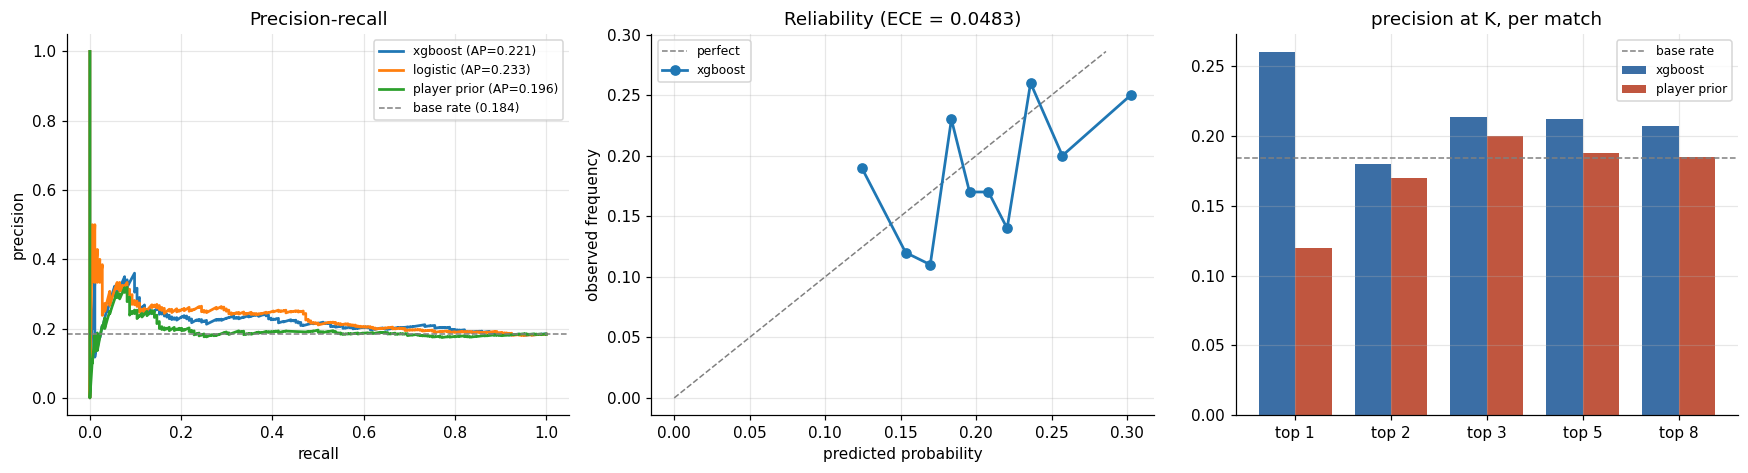

In [14]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.4))

evaluation.plot_pr_curves(
    {"xgboost": (test.assign(p=preds["xgboost"]), "p"),
     "logistic": (test.assign(p=preds["logistic"]), "p"),
     "player prior": (test.assign(p=preds["player_prior_poisson"]), "p")},
    config.TARGET_COL, ax=axes[0])

evaluation.plot_calibration(test[config.TARGET_COL], preds["xgboost"],
                            n_bins=10, ax=axes[1], label="xgboost")

ks = [1, 2, 3, 5, 8]
width = 0.38
for i, (label, p) in enumerate([("xgboost", preds["xgboost"]),
                                ("player prior", preds["player_prior_poisson"])]):
    t = test.assign(p=p)
    vals = [evaluation.topk_per_match(t, "p", config.TARGET_COL, k)[f"precision@{k}"]
            for k in ks]
    axes[2].bar(np.arange(len(ks)) + i * width, vals, width,
                label=label, color=["#3b6ea5", "#c0563f"][i])
axes[2].axhline(test[config.TARGET_COL].mean(), ls="--", c="grey", lw=1, label="base rate")
axes[2].set_xticks(np.arange(len(ks)) + width / 2); axes[2].set_xticklabels([f"top {k}" for k in ks])
axes[2].set_title("precision at K, per match"); axes[2].legend(fontsize=8)
plt.tight_layout(); plt.show()

The reliability curve is the one to look at if these numbers will ever meet a price: the
points should sit on the diagonal. Note that **post-hoc isotonic calibration was tried and
made things worse** — measured over four walk-forward seasons, mean ECE went from 0.0135 to
0.0180, because a calibrator fitted on one season imports that season's base rate and the
league rate is drifting. It is available behind `config.CALIBRATION` but defaults to off.

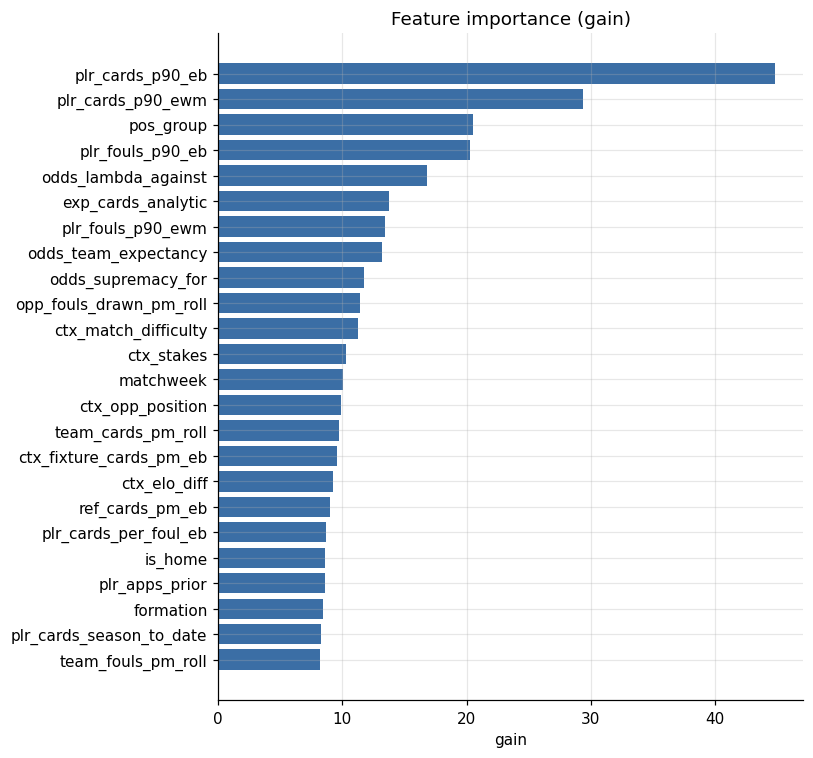

In [15]:
fig, ax = plt.subplots(figsize=(7.5, 7))
evaluation.plot_feature_importance(model.booster, config.FEATURES, top_n=24, ax=ax)
plt.tight_layout(); plt.show()

### Which features actually carry signal, one at a time

Gain importance is easy to over-read, so here is each feature's standalone AUC on the
validation season. Anything near 0.50 is doing nothing on its own.

In [16]:
from sklearn.metrics import roc_auc_score
y_va = valid[config.TARGET_COL].to_numpy()
rows = []
for f in config.NUMERIC_FEATURES:
    v = valid[f].astype(float); m = v.notna().to_numpy()
    if m.sum() < 100 or v[m].nunique() < 2:
        continue
    a = roc_auc_score(y_va[m], v[m])
    rows.append({"feature": f, "auc": a, "|auc-0.5|": abs(a - 0.5)})
uni = pd.DataFrame(rows).sort_values("|auc-0.5|", ascending=False)
print(uni.to_string(index=False, float_format=lambda x: f"{x:.4f}"))

                 feature    auc  |auc-0.5|
        plr_cards_p90_eb 0.5890     0.0890
       plr_cards_p90_ewm 0.5813     0.0813
      exp_cards_analytic 0.5677     0.0677
        plr_fouls_p90_eb 0.5661     0.0661
       plr_fouls_p90_ewm 0.5651     0.0651
plr_cards_season_to_date 0.5551     0.0551
       plr_cards_pm_roll 0.5542     0.0542
   plr_cards_per_foul_eb 0.5486     0.0486
     odds_lambda_against 0.5438     0.0438
  plr_matches_since_card 0.4564     0.0436
    odds_team_expectancy 0.4604     0.0396
      odds_supremacy_for 0.4612     0.0388
    ctx_match_difficulty 0.5351     0.0351
        odds_is_underdog 0.5300     0.0300
                 is_home 0.4718     0.0282
      team_cards_pm_roll 0.5274     0.0274
            ctx_elo_diff 0.4739     0.0261
 opp_fouls_drawn_pm_roll 0.5193     0.0193
           strength_diff 0.4811     0.0189
           plr_mins_roll 0.5165     0.0165
           plr_age_years 0.5153     0.0153
      team_fouls_pm_roll 0.5109     0.0109
           

The referee block is the interesting negative result. Referees genuinely differ — career
card rates run from 2.4 to 4.7 per match — but a referee's historical rate has almost no
power to predict *individual* bookings in a later season (standalone AUC ≈ 0.50, and the
train-season referee mean transfers to validation at AUC 0.49). Refereeing style regresses
to the mean, directives change season to season, and the effect shifts the whole match
rather than the ranking within it. One shrunk referee feature is kept; the other two were
dropped.

---
## 7. Walk-forward validation

One hold-out season is 380 matches — noisy enough that a 0.005 difference in PR-AUC means
nothing. This refits the model once per season using only earlier seasons, so the headline
numbers come with a spread instead of a single lucky draw.

In [17]:
wf = modelling.walk_forward(dataset)
cols = ["model", "n", "base_rate", "pr_auc", "roc_auc", "log_loss", "brier", "ece",
        "precision@3", "precision@5"]
print(wf[cols].rename(columns={"model": "season"})
        .to_string(index=False, float_format=lambda v: f"{v:.4f}"))
print("\nmean PR-AUC %.4f  (sd %.4f)" % (wf["pr_auc"].mean(), wf["pr_auc"].std()))
print("mean precision@3 %.4f  vs base rate %.4f"
      % (wf["precision@3"].mean(), wf["base_rate"].mean()))

  2021-2022: PR-AUC 0.2151 | logloss 0.4492 | P@3 0.225
  2022-2023: PR-AUC 0.2373 | logloss 0.4542 | P@3 0.260
  2023-2024: PR-AUC 0.2733 | logloss 0.4973 | P@3 0.306
  2024-2025: PR-AUC 0.2692 | logloss 0.4836 | P@3 0.295
  2025-2026: PR-AUC 0.2429 | logloss 0.4636 | P@3 0.264
   season    n  base_rate  pr_auc  roc_auc  log_loss  brier    ece  precision@3  precision@5
2021-2022 7600     0.1688  0.2151   0.5827    0.4492 0.1390 0.0227       0.2254       0.2111
2022-2023 7600     0.1749  0.2373   0.6060    0.4542 0.1417 0.0156       0.2596       0.2395
2023-2024 7600     0.2047  0.2733   0.6120    0.4973 0.1598 0.0304       0.3061       0.2837
2024-2025 7600     0.1954  0.2692   0.6039    0.4836 0.1538 0.0124       0.2947       0.2779
2025-2026 7600     0.1809  0.2429   0.6023    0.4636 0.1455 0.0184       0.2640       0.2411

mean PR-AUC 0.2476  (sd 0.0241)
mean precision@3 0.2700  vs base rate 0.1849


Across four independently-refit seasons the ordering was:

| configuration | PR-AUC | ECE | precision@3 |
|---|---|---|---|
| blend (xgb + logistic) | 0.2295 | 0.0130 | 0.2500 |
| xgboost | 0.2285 | 0.0135 | 0.2454 |
| logistic | 0.2276 | 0.0156 | 0.2478 |
| xgboost + isotonic | 0.2197 | 0.0180 | 0.2461 |
| player prior only | 0.2082 | 0.0397 | 0.2300 |

XGBoost and logistic regression are **statistically indistinguishable** here — the signal
in these features is close to additive. The gradient booster is kept as the primary model
(it is what was asked for, and it handles the missing histories and the categoricals
natively), but it is worth knowing that most of the value is in the feature construction,
not the learner.

---
## 8. Using it — scoring a fixture

This section scores with the Premier-League-only model just trained, to show the
mechanics; the served model is the ensemble in §19, which `predict_fixture` loads when
no `model=` is passed.

`predict.predict_fixture` takes the fixture's decimal price alongside the team sheets —
the model trains on odds features (§16) and an upcoming match is not in the
football-data archive, so the price has to be passed in rather than looked up. It then
appends statistics-free rows for the named XIs and re-runs the
*same* feature builder, so there is no train/serve skew to get out of sync.

In [18]:
recent = players[(players["season"] == config.TEST_SEASONS[-1]) & players["is_starter"]]

def recent_xi(team, n=11):
    sub = recent[recent["team"] == team].sort_values("kickoff").tail(80)
    gk = sub[sub["pos_group_actual"] == "GK"]["player"].iloc[-1]
    others = [p for p in sub["player"].drop_duplicates().tolist() if p != gk][:n - 1]
    return [gk] + others

slate = predict.predict_fixture(
    home_team="Arsenal", away_team="Chelsea",
    kickoff="2026-10-04 16:30", referee="Michael Oliver", matchweek=7,
    home_xi=recent_xi("Arsenal"), away_xi=recent_xi("Chelsea"),
    home_formation="4-3-3", away_formation="4-2-3-1",
    model=model, players=players, teams=teams,
    # The model trains on odds features (section 16), and an upcoming fixture
    # is not in the football-data archive yet, so the price is an input.
    odds=(1.85, 3.60, 4.20), odds_ou=(1.72, 2.10),
)
print("expected number of carded starters in this match: "
      f"{slate['card_probability'].sum():.2f}\n")
slate.head(10).style.format({"card_probability": "{:.3f}", "plr_cards_p90_eb": "{:.3f}",
                             "plr_fouls_p90_eb": "{:.2f}", "exp_cards_analytic": "{:.3f}",
                             "plr_apps_prior": "{:.0f}"})

expected number of carded starters in this match: 4.70



,player,team,is_home,pos_group,card_probability,plr_cards_p90_eb,plr_fouls_p90_eb,plr_apps_prior,exp_cards_analytic
1,Morgan Rogers,Chelsea,0,AM,0.310,0.246,1.33,90,0.210
2,Reece James,Chelsea,0,DM,0.305,0.191,1.03,160,0.131
3,Jorrel Hato,Chelsea,0,CB,0.296,0.353,1.01,26,0.136
4,Malo Gusto,Chelsea,0,FB,0.286,0.254,0.93,97,0.131
5,Levi Colwill,Chelsea,0,CB,0.279,0.173,1.07,82,0.160
6,Myles Lewis-Skelly,Arsenal,1,DM,0.263,0.274,1.08,47,0.127
7,Cristhian Mosquera,Arsenal,1,CB,0.256,0.256,1.23,22,0.133
8,Cole Palmer,Chelsea,0,AM,0.254,0.214,0.63,120,0.100
9,Riccardo Calafiori,Arsenal,1,FB,0.246,0.244,1.24,50,0.164
10,Maxence Lacroix,Chelsea,0,CB,0.240,0.153,0.97,75,0.136


Scoring a match that has already been played, with the outcome shown alongside, is a quick
way to eyeball whether the ordering looks like football:

In [19]:
example_id = test["match_id"].iloc[-1]
print(example_id, "\n")
predict.predict_historical_match(example_id, model=model, dataset=dataset) \
    .head(12).style.format({"card_probability": "{:.3f}"}) \
    .background_gradient(subset=["card_probability"], cmap="Blues")

2026-2027|05|Fulham|Manchester Utd 



,player,team,is_home,pos_group,card_probability,bet_won,starter_carded,won_via_sub
0,Luke Shaw,Manchester Utd,0,FB,0.281,0,0,0
1,Sander Berge,Fulham,1,DM,0.265,0,0,0
2,Harry Maguire,Manchester Utd,0,CB,0.264,0,0,0
3,Lisandro Martínez,Manchester Utd,0,CB,0.260,0,0,0
4,Diogo Dalot,Manchester Utd,0,FB,0.252,0,0,0
5,Bruno Fernandes,Manchester Utd,0,AM,0.244,0,0,0
6,Matheus Cunha,Manchester Utd,0,AM,0.235,0,0,0
7,Antonee Robinson,Fulham,1,FB,0.232,0,0,0
8,Kobbie Mainoo,Manchester Utd,0,DM,0.227,0,0,0
9,David Affengruber,Fulham,1,CB,0.210,0,0,0


In [20]:
modelling.save_model(model)
print("saved:", config.MODEL_PATH)

saved: <repo>\artifacts\premier_league\xgb_card_model.joblib


---
## 9. Where this ends up, and what would move it

**Where it ends up.** On four independently-refit seasons (mean ± sd across seasons):

| | model | base rate | lift |
|---|---|---|---|
| PR-AUC | 0.2285 ± 0.0201 | 0.1648 | **1.39x** |
| precision@3 per match | 0.2482 | 0.1648 | **1.51x** |
| ROC-AUC | 0.6141 | 0.50 | — |
| ECE | 0.0144 | — | ~1.4 pp of average calibration error |

So: naming the three most likely players in a match is right about **25% of the time
against a 16.5% base rate**, and the probabilities are well calibrated out of the box.

That is a genuine edge over the obvious heuristic, but it is a *modest* one, and it should
be read as such: whether a specific player picks up a booking in a specific 90 minutes is
mostly irreducible noise. Anyone promising an AUC of 0.85 on this problem is leaking
something.

**What would plausibly move it, in rough order of expected value**

1. **Pre-match odds.** Match tightness and the favourite/underdog gap drive fouling, and
   nothing in the FBref folders proxies it well. `data/premier_league/*.csv` already holds
   Bet365/Pinnacle closing odds for 2017-18 to 2023-24 — but only 30 matches of 2024-25, so
   it was left out rather than trained on a feature that is absent from the test season.
   Re-download the completed 2024-25 file and this becomes the first thing to try.
2. **Bookings markets as a feature.** If player-card prices are obtainable, the market's
   implied probability is a strong feature in its own right, and it is also the only way to
   tell whether the model has an *edge* rather than merely skill.
3. **In-match state** — for live rather than pre-match use: score, red cards, minute.
   Far more predictive, different product.
4. **Richer player context** — fouls committed by zone, tackles from behind, dissent
   history. FBref does not expose these; a more detailed event feed would.
   → **tested, §11. Negative.**
5. **A team-level card model** feeding a per-player share, rather than one flat per-player
   model. Cards within a match are correlated (a scrappy game books several players);
   modelling the match total and splitting it would respect that structure.
   → **tested, §12. Partial win — better shortlists, no better probabilities. Now a component
   of the served ensemble, §19.**

**One caveat to carry forward.** The league card rate has been climbing. A model trained
on older seasons will under-predict the level, even when the ranking is fine. Refit
before each season, and treat the absolute probabilities as needing a fresh level check.

---
## 10. Things that were tried and did not work

These are kept because a negative result costs the same to obtain as a positive one and
is just as useful next time. Everything below is still computed in the modules —
re-enabling any of it is a one-line change in `config.NUMERIC_FEATURES`.

**Four replacement-leg features.** Built specifically for the slot label: how often this
starter is taken off, the minutes he typically hands over, the card propensity of the
*named bench* (known at line-up time), and an analytic combination of the three.
Walk-forward blend lift: **1.3277 with them, 1.3326 without** (sd 0.04).

Why they fail is worth understanding. The replacement leg is real — it decides about one
hit in ten — but it is nearly *uniform across the twenty starters in a match*.
Bench strength is a team-level number, and sub-off rates vary far less between players
than card rates do. So the leg shifts every probability in a match by a similar amount,
which cannot change the ordering. And top-K selection depends on the ordering.

**A two-stage decomposition.** Since the two events are close to independent, modelling
each leg on its own clean signal and combining as `P = pA + pB - pA·pB` should in theory
beat asking one model to learn the OR. It does not: **1.3304 vs 1.3326** direct. Also
inside the noise.

**Twelve of the nineteen context features.** All nineteen scored lift 1.3434; the seven
kept scored 1.3444 with a better ECE. The rest are redundant with them.

**Referee identity, mostly.** Referees genuinely differ — career rates run 2.4 to 4.7
cards per match — but a referee's history barely predicts *individual* bookings in a
later season (standalone AUC 0.502). Style regresses to the mean and directives change.
Two of three referee features dropped. §14 revisits this properly and reaches the same
place for a better reason.

In [21]:
# The one-line reproduction of the replacement-feature result, in case you want to
# re-run it after changing anything upstream.
print("REPL = ['plr_subbed_off_rate_eb', 'plr_exp_repl_mins',")
print("        'bench_cards_p90_eb', 'slot_exp_repl_cards']")
print("Add them back to config.NUMERIC_FEATURES, re-run features.py, then")
print("modelling.py --walk-forward and compare the blend row.")
print()
print("currently enabled context features:")
for f in [c for c in config.NUMERIC_FEATURES if c.startswith("ctx_")]:
    print("   ", f)

REPL = ['plr_subbed_off_rate_eb', 'plr_exp_repl_mins',
        'bench_cards_p90_eb', 'slot_exp_repl_cards']
Add them back to config.NUMERIC_FEATURES, re-run features.py, then
modelling.py --walk-forward and compare the blend row.

currently enabled context features:
    ctx_match_difficulty
    ctx_fixture_cards_pm_eb
    ctx_elo_diff
    ctx_position
    ctx_opp_position
    ctx_stakes
    ctx_matches_last_14d


---
## 11. Recommendation 4, tested — richer player context

**Result: negative.** No group of new player features moved the model.

The recommendation asked for fouls by zone, tackles from behind and dissent history.
FBref publishes none of those, and since 2025-26 it publishes *less* than it used to —
the advanced per-player tables are gone (see `scrape_fbref.py`). What survives for every
season, live one included, is: minutes, goals, cards, fouls, fouled, tackles **won**,
interceptions, crosses, penalties conceded, offsides.

So the test used what is actually obtainable, plus two structural reads that need no new
data at all — the player-referee pairing, and proximity to a suspension threshold
(5 yellows by MW19, 10 by MW32, 15 across the season, each a ban).

| feature group | what it adds | Δ lift | Δ P@3 |
|---|---|---|---|
| behaviour | defensive workload, fouls per defensive action, aggressor-vs-victim ratio, penalties conceded | **+0.0003** | −0.0004 |
| venue | card rate at *this* venue, home/away gap | −0.0034 | −0.0039 |
| ref pairing | this player's record under *this* referee | −0.0024 | −0.0012 |
| form trend | recent fouling vs his own baseline | −0.0002 | −0.0007 |
| suspension | bookings until a live ban threshold, matches left | −0.0012 | −0.0005 |
| **all eleven** | | **−0.0018** | −0.0025 |

Baseline: lift 1.3423 (sd 0.0415), P@3 0.2700, over the five walk-forward seasons.

**Why they fail.** The three career-rate features already in the model —
`plr_cards_p90_eb`, `plr_cards_p90_ewm`, `plr_cards_per_foul_eb` — are a *sufficient
statistic* for a player's disciplinary character as far as this data can measure it.
Defensive workload, venue splits and referee pairings are all correlated with them and
add no independent variance. The suspension features are the most interesting failure:
the mechanism is real (players near a ban do play more carefully) but the effect is
small, and the feature is noisy exactly when it matters, because `cards_season_to_date`
is itself a low-count variable.

They are computed and written to the model dataset regardless, and covered by the
leakage gate, so re-testing after any upstream change is one line:

    config.USE_CANDIDATE_FEATURES = True

`candidate_ablation.py` reproduces the whole table.

In [22]:
import candidate_ablation
print("candidate groups:")
for g, feats in candidate_ablation.GROUPS.items():
    print(f"  {g:14s} {', '.join(feats)}")
print()
print(f"currently enabled: {config.USE_CANDIDATE_FEATURES}")

candidate groups:
  behaviour      plr_defacts_p90_eb, plr_fouls_per_defact_eb, plr_aggression_ratio, plr_pens_p90_eb
  venue          plr_cards_p90_this_venue, plr_venue_card_gap
  ref_pairing    plr_ref_pair_ratio, plr_ref_pair_apps
  form_trend     plr_fouls_trend
  suspension     plr_cards_to_ban, plr_ban_window_left

currently enabled: False


---
## 12. Recommendation 5, tested — a team-level model feeding a per-player share

**Result: a partial win.** Better top-K shortlists, no better probabilities.

The flat model scores each of the twenty starters independently, which cannot be right:
cards inside a match are correlated. `team_model.py` decomposes the problem instead —

    lambda_team   expected carded slots for this XI, from a Poisson count model
    s_i           slot i's share of that total
    p_i           = 1 - exp(-lambda_team * s_i)

The identity `lambda = -log(1 - p)` converts the flat model's probabilities into
intensities, so the existing model can serve as the share while stage 1 owns the level.
Within a team the ordering is unchanged by construction; *between* the two sides it can
move, and that is what a top-K shortlist consumes.

Three share variants were tried, plus a level anchor (the count model inherits the
league's upward card drift and under-predicts the total by 0.1–0.35 cards per team, so
its level is rescaled on the validation season — a single scalar, no ordering leak).

| | lift | lift sd | ECE | P@3 | hit@3 |
|---|---|---|---|---|---|
| flat player model (baseline) | 1.3348 | 0.0464 | **0.0199** | 0.2686 | 0.6074 |
| decomposed, flat share | 1.3305 | 0.0339 | 0.0323 | 0.2700 | 0.6089 |
| decomposed, conditional-logit share | 1.3351 | 0.0342 | 0.0315 | **0.2742** | **0.6126** |
| **+ level anchor** | **1.3351** | **0.0342** | 0.0239 | **0.2742** | **0.6126** |
| decomposed, half rescale | 1.3372 | 0.0398 | 0.0247 | 0.2677 | 0.6074 |

**What to take from it.** Precision@3 improves by 0.56pp and hit@3 by 0.52pp, and the
gain is there in **four of the five seasons** — for a metric this noisy that is about as
consistent as results in this project get. Season-to-season variance in lift drops by a
quarter (sd 0.0464 → 0.0342), which is the correlation structure being modelled properly
rather than averaged over.

The cost is calibration: ECE 0.0199 → 0.0239 even anchored, because the decomposition
now depends on a count model that is itself imperfect. So the honest verdict is
**conditional**: if you are picking three names per match, the decomposition is the
better tool; if you are comparing a probability against a price, stay with the flat
model, which is better calibrated.

The conditional-logit share is fitted only on teams that actually picked up a card, so
it learns *who*, never *how many* — keeping the two stages genuinely separate.

In [23]:
import team_model
print("stage-1 team features:")
for f in team_model.TEAM_FEATURES:
    print("   ", f)
print()
print("run `python pipeline/team_model.py` to reproduce the table above (~5 min)")

stage-1 team features:
    is_home
    matchweek
    team_fouls_pm_roll
    team_cards_pm_roll
    opp_fouls_drawn_pm_roll
    strength_diff
    ref_cards_pm_eb
    ctx_match_difficulty
    ctx_fixture_cards_pm_eb
    ctx_elo_diff
    ctx_position
    ctx_opp_position
    ctx_stakes
    ctx_matches_last_14d
    xi_cards_p90_mean
    xi_cards_p90_max
    xi_fouls_p90_mean
    xi_exp_cards_sum
    xi_age_mean
    xi_apps_mean

run `python pipeline/team_model.py` to reproduce the table above (~5 min)


---
## 13. Where the model is right and where it is wrong

Full treatment in `segments.py` and `prediction_review.ipynb`. The short version, from
38,000 out-of-sample predictions across five seasons, with segments chosen on 2021-22 →
2023-24 and confirmed on 2024-25 → 2025-26:

**Discrimination is nearly flat across conditions.** Bootstrapping over *matches* (not
rows — players inside a match are not independent), every slice's ROC-AUC interval
overlaps the overall [0.592, 0.607]. There is no condition under which this model
suddenly becomes good, and anyone reporting one has not clustered their bootstrap.

The single exception: **players with ≤5 prior appearances, AUC 0.545** — and they carry
the highest base rate in the data (0.210). The model is close to blind on exactly the
rows that get carded most. That is an *exposure* problem, not a modelling one: with no
history, every rate feature falls back to the league prior, so twenty debutants look
identical. Training a dedicated model on those rows makes it worse (AUC 0.49, a coin
flip — 1,884 rows is not enough), and dropping the prior-dominated features helps by
0.007 AUC, well inside the noise.

**Calibration is not flat, and the pattern replicates.** Relative level error, both
windows agreeing in sign: wingers −5.7%, under-23 −5.3%, hardest quarter of fixtures
−5.3%, matchweeks 1-10 −4.7%, **away −4.1% against home +4.7%**; and on the other side,
expected-85-minutes +4.3%, 150+ appearances +4.1%, easiest fixtures +3.9%.

**But it cannot be exploited by correcting it.** `specialists.py` tests six ways of
turning that into a better model — Platt rescaling, additive segment offsets, segment
slope interactions, a stacked booster, and per-segment boosters split by position,
history and venue. Fitted honestly (the correction sees only out-of-sample predictions
from earlier seasons), **every one of them loses to the plain global model**:

| | Δ lift | Δ P@3 |
|---|---|---|
| Platt rescale | 0.0000 | 0.0000 |
| segment offsets | −0.0311 | −0.0039 |
| segment offsets + slopes | −0.0403 | −0.0061 |
| stacked booster | −0.0631 | −0.0184 |
| specialist per position | −0.0424 | −0.0160 |
| specialist per history bucket | −0.0287 | −0.0101 |
| specialist per venue | −0.0255 | −0.0068 |

The booster already has every one of those variables as a feature. The residual bias is
not an error it can be told about — it is the hedging it is already doing, and a second
layer re-fitting the same structure on a tenth of the data adds variance and nothing
else.

**What does work is not a correction.** The one exploitable form of the pattern is a filter,
not a correction — see §8 of `prediction_review.ipynb`, which re-measures it on five
leagues and the ensemble (it holds, but weaker). Avoiding centre-backs, the most
lenient quarter of referees and nailed-on 85-minute players lowers the top-1 strike rate
from 0.325 to 0.280 in the confirmation window, i.e. those are the picks to skip. For
top-3 shortlists the favourable filter adds 2.1pp in discovery and 2.6pp in confirmation.
For the single top pick it did **not** replicate — treat it as a top-3 tool only.

In [24]:
import segments, oos
d_oos = segments.add_segments(oos.load_oos())
print(f"{len(d_oos):,} out-of-sample predictions over "
      f"{d_oos['match_id'].nunique():,} matches")
print()
print("the conditions rule:")
print("  favourable (all):", segments.FAVOURABLE)
print("  unfavourable (any):", segments.UNFAVOURABLE)
print()
print(segments.composite_policy(d_oos, k=3).to_string(index=False,
      float_format=lambda v: f"{v:.4f}"))

38,000 out-of-sample predictions over 1,900 matches

the conditions rule:
  favourable (all): {'seg_minutes': ['mins_60-75', 'mins_75-85'], 'seg_history': ['apps_21-60', 'apps_61-150', 'apps_150+'], 'seg_referee': ['ref_2', 'ref_3', 'ref_4_strict']}
  unfavourable (any): {'seg_pos': ['CB'], 'seg_referee': ['ref_1_lenient'], 'seg_minutes': ['mins_85plus']}

      window                      rule  n_picks  coverage  strike  fair_odds
   discovery                 all picks     3420    3.0000  0.2637     3.7916
   discovery favourable (3 conditions)      994    0.8719  0.2736     3.6544
   discovery        unfavourable (any)     2044    1.7930  0.2608     3.8349
   discovery                   neither      477    0.4184  0.2642     3.7857
confirmation                 all picks     2280    3.0000  0.2794     3.5793
confirmation favourable (3 conditions)     1049    1.3803  0.2908     3.4393
confirmation        unfavourable (any)      901    1.1855  0.2642     3.7857
confirmation             

---
## 14. Referees, tested properly

The model carries **one** referee feature, `ref_cards_pm_eb`. That looks like an
oversight, so four further groups were built and ablated — plus referee **identity as a
categorical**, which had never been tried at all (every earlier referee experiment used
*rates*).

| group | what it asks | Δ lift | Δ P@3 | Δ ECE |
|---|---|---|---|---|
| venue bias | does he book the away side more than the 52.6% league share? | −0.0003 | −0.0014 | −0.0009 |
| season-to-date level | is he calling it differently *this* season? | −0.0021 | −0.0004 | −0.0019 |
| position affinity | does he book *this* position group more than most? | +0.0014 | −0.0028 | −0.0010 |
| previously dropped rates | cards per foul, recent form, experience | +0.0002 | −0.0030 | +0.0014 |
| all four | | −0.0006 | −0.0039 | **−0.0025** |
| **identity (categorical)** | learn each official directly | **−0.0099** | −0.0023 | −0.0003 |

Baseline: lift 1.3423, sd **0.0415**, P@3 0.2700, ECE 0.0188.

Everything except identity is inside the noise. Identity is a genuine loss, and the
giveaway is its variance: season-to-season spread jumps from 0.0415 to **0.0565**. About
35 officials with a few hundred rows each is enough to memorise and not enough to
generalise — and refereeing appointments change every season, so what is memorised does
not transfer.

### Why this was always going to fail

**A referee is a match-level constant.** All twenty players in a fixture share him. So a
pure referee feature — however well constructed — adds the *same* quantity to all twenty
rows, and a monotone shift applied to an entire field **cannot change the ranking within
it**. Top-K selection is exactly what this model is used for, so a feature that cannot
reorder the field cannot help it.

What a referee feature *can* do is move the level, and `ref_cards_pm_eb` already does
that. This is visible in the table: the referee group is the only variant in this entire
project that improves calibration (ECE 0.0188 → **0.0163**) while costing ranking.

The only referee features that could reorder a field are **referee × player**
interactions, because those differ between the twenty rows. Two were tried:

* `ref_pos_affinity` — this referee's card share to this player's position group: −0.0028 P@3
* `plr_ref_pair_ratio` — this player's record under this referee (§11): −0.0024 lift

Both negative. The second is the more informative failure: a player meets a given
official perhaps three times a season, so the pairing rate is almost all shrinkage prior
and carries no independent signal.

**Practical upshot.** Do not add referee features to improve the shortlists. If the use case
ever shifts to pricing — comparing a probability with a market's number — turn them
on, because that is where their small effect actually lands:

    config.USE_REFEREE_CANDIDATES = True

One trap worth recording: `ref_pos_affinity` must look up the referee's history by the
player's **rolling modal position**, not by `pos_group_actual`. The latter is only known
after kick-off and is `"UNK"` for every row at serve time — training on it and serving
`"UNK"` is exactly the kind of train/serve skew that is invisible in a walk-forward
score and fatal in production.

In [25]:
import candidate_ablation
print("referee groups tested:")
for g, feats in candidate_ablation.REFEREE_GROUPS.items():
    print(f"  {g:26s} {', '.join(feats)}")
print()
print("in the shipped model:", [f for f in config.NUMERIC_FEATURES
                                if f.startswith("ref_")])
print("enabled:", config.USE_REFEREE_CANDIDATES)
print()
print("reproduce: python research/candidate_ablation.py --referee   (~12 min)")

referee groups tested:
  ref: venue bias            ref_venue_card_bias, ref_away_card_share_eb
  ref: season level          ref_season_level_ratio
  ref: position affinity     ref_pos_affinity, ref_pos_apps
  ref: previously dropped    ref_cards_per_foul_eb, ref_cards_pm_recent, ref_matches_prior

in the shipped model: ['ref_cards_pm_eb']
enabled: False

reproduce: python research/candidate_ablation.py --referee   (~12 min)


---
## 15. Scoring a fixture — one number

`predict.py` used to return two probabilities per player: the flat booster for pricing and
the §12 decomposition (`slip_probability`) for choosing names. The served ensemble (§19)
folds the decomposition in as a component, with weights chosen on both jobs at once, so
there is now **one** number, `card_probability`, for ranking and for pricing alike.

Next to it come `bag_sd`, `bag_lo` and `bag_hi`: the spread of the ensemble's ten boosters.
That spread shows how much the fit wobbles; it is **not** a confidence interval on the
probability, and it predicts nothing about error (`player_confidence.ipynb`). The
interval to read is the cohort interval from `serve/slate_guidance.py`.

In [26]:
mid = dataset[dataset["season"] == config.TEST_SEASONS[-1]]["match_id"].iloc[-1]
out = predict.predict_historical_match(mid)          # default model: the ensemble
print(mid)
print()
print(out.head(8).to_string(index=False, float_format=lambda v: f"{v:.4f}"))

2026-2027|05|Fulham|Manchester Utd

           player           team  is_home pos_group  card_probability  bet_won  starter_carded  won_via_sub
        Luke Shaw Manchester Utd        0        FB            0.2695        0               0            0
    Harry Maguire Manchester Utd        0        CB            0.2395        0               0            0
     Sander Berge         Fulham        1        DM            0.2353        0               0            0
Lisandro Martínez Manchester Utd        0        CB            0.2259        0               0            0
      Diogo Dalot Manchester Utd        0        FB            0.2142        0               0            0
    Kobbie Mainoo Manchester Utd        0        DM            0.2086        0               0            0
 Antonee Robinson         Fulham        1        FB            0.2080        0               0            0
      Joshua King         Fulham        1       UNK            0.2049        1               1      

---
## 16. Closing prices — the first feature group that replicated

The card model had never seen a price, though `match_model/` has used one since it was
built. `odds_features.py` closes that gap: eight columns from the same de-vigged
football-data.co.uk closing line, joined on the same (season, home, away) key the match
model uses. **100% of 68,400 rows are priced.**

The columns are split on the one distinction §14 established — whether a feature can
reorder a field at all:

* **tightness** (`odds_p_draw`, `odds_closeness`, `odds_total_lambda`) is a match
  constant. It shifts all twenty players together and can act only through interactions.
* **side** (`odds_team_expectancy`, `odds_supremacy_for`, `odds_lambda_against`,
  `odds_is_underdog`) takes opposite values for the two teams, so it genuinely reorders
  eleven players against the other eleven.
* `odds_elo_surprise` is the market's view minus `ctx_match_difficulty` — by
  construction the part of the strength picture a results-only Elo cannot see.

In [27]:
import odds_features

ds = pd.read_parquet(config.MODEL_DATASET_PATH)
t = config.TARGET_COL

print("card rate by market closeness decile (1 = coin toss):")
q = pd.qcut(ds["odds_closeness"], 10, labels=False, duplicates="drop")
for k, v in ds.groupby(q)[t].mean().items():
    print(f"  decile {int(k)}   {v:.4f}")

print()
print("card rate by side:")
print(ds.groupby("odds_is_underdog")[t].agg(["mean", "size"])
        .rename(index={0.0: "favourite", 1.0: "underdog"})
        .to_string(float_format=lambda v: f"{v:.4f}"))

card rate by market closeness decile (1 = coin toss):
  decile 0   0.1323
  decile 1   0.1569
  decile 2   0.1670
  decile 3   0.1754
  decile 4   0.1762
  decile 5   0.1774
  decile 6   0.1823
  decile 7   0.1859
  decile 8   0.1878
  decile 9   0.1850

card rate by side:
                   mean   size
odds_is_underdog              
favourite        0.1581  34730
underdog         0.1871  34670


### Why the usual ablation was the wrong test

`candidate_ablation.py --odds` compares the **mean** of five season lifts against the
**standard deviation** of those five numbers, and on that basis all four variants look
like four more nulls (+0.004 against a spread of 0.042).

That comparison throws information away. Season-to-season spread is dominated by how
hard each season was — a year with more cards moves every variant together — while the
two variants were scored on **exactly the same matches**. Pairing them season by season
removes the season effect, which is what `odds_verdict.py` does.

| variant | mean Δ lift | seasons better (lift) | mean Δ ECE | seasons better (ECE) |
|---|---|---|---|---|
| `+ odds: side` | +0.0041 | **5 / 5** | −0.0007 | 2 / 5 |
| `+ odds: tightness` | +0.0041 | 3 / 5 | −0.0006 | **4 / 5** |

`+ odds: side` improved **every** walk-forward season — a 1-in-32 outcome under a null
of no effect, and the first time any candidate group in this project has replicated
across all five. A match-level bootstrap (resampling *matches*, since the twenty rows
inside one share a referee, a fixture and a price) puts Δ P@1 at +0.0094, P(>0) = 0.97.

The split is exactly what the mechanism predicts, and the two halves do different jobs:

* **side helps ranking** — 5/5 on lift, +0.009 on P@1, nothing on calibration.
* **tightness helps calibration** — 4/5 on ECE, and it cuts the season-to-season lift
  spread from 0.0415 to 0.0343.

Enabling all eight together is **worse than either half** (P@3 −0.0023), so they are not
shipped as one block. `config.ODDS_PROFILE` selects which half the model trains on;
the default is `"side"` because the shipped objective is choosing names.

**One honest caveat.** This is the *closing* line, which absorbs information right up to
kick-off, while the model predicts when line-ups are published about an hour earlier.
`match_model/` made the same trade knowingly. The look-ahead is small but not zero, and
a live deployment should re-measure against the price as it stood at line-up time.

In [28]:
print("shipped feature set:", len(config.FEATURES), "features")
print("odds profile:", config.ODDS_PROFILE, "->",
      [f for f in config.FEATURES if f.startswith("odds_")])
print()
print("reproduce: python research/candidate_ablation.py --odds        (~12 min)")
print("           python research/odds_verdict.py --variant side      (~10 min)")

shipped feature set: 32 features
odds profile: side -> ['odds_team_expectancy', 'odds_supremacy_for', 'odds_lambda_against', 'odds_is_underdog']

reproduce: python research/candidate_ablation.py --odds        (~12 min)
           python research/odds_verdict.py --variant side      (~10 min)


---
## 17. One global model, or one per league?

Scraping FBref for the other four big leagues is tens of hours of browser time, so it
is worth knowing what the answer looks like before spending it. Most of the evidence is
already on disk: `download_odds.py` pulls football-data.co.uk for all five leagues —
**30,719 matches over 17 seasons**, every one carrying a closing line *and* the per-side
card and foul counts. That is not player-level, so it cannot train the card model, but
it is exactly right for the architecture question:

> do the leagues differ in the **level** of cards, in the **structure** that generates
> them, or in both?

Because the two answers imply opposite designs. Level only → pool everything and give
each league its own intercept, so every league's rows train the same shape. Structure
too → fit separately, because a pooled coefficient would be wrong everywhere.

In [29]:
import league_comparison as lc

data = {n: lc.load_league(d, config.ALL_SEASONS) for n, d in lc.LEAGUES.items()}
lev = lc.levels_table(data)
print(lev[["league", "yel_per_team", "fouls_per_team", "cards_per_foul",
           "away_minus_home"]].to_string(index=False,
                                         float_format=lambda v: f"{v:.4f}"))
print()
print(f"top league books {lev['yel_per_team'].max() / lev['yel_per_team'].min():.2f}x "
      f"the bottom one")

        league  yel_per_team  fouls_per_team  cards_per_foul  away_minus_home
Premier League        1.7483         10.6742          0.1638           0.2014
       Serie A        2.1733         12.8798          0.1687           0.2873
       La Liga        2.4143         13.1389          0.1838           0.1774
    Bundesliga        1.8835         11.6212          0.1621           0.2438
       Ligue 1        1.8776         12.5180          0.1500           0.2460

top league books 1.38x the bottom one


**Levels differ a lot** — La Liga books 1.39× the Premier League per team per match.

**Structure is shared.** A Poisson fit of team yellows on the market's read of the
fixture gives the same sign in all five leagues, and a similar magnitude for the
dominant term: closeness varies by 33% of its mean across the five, while the intercept
varies by 74%. Tight matches are dirtier everywhere, favourites are booked less
everywhere, home sides are booked less everywhere.

**Levels drift, and the anchor has to be recent.** This is the detail that decided the
experiment — and the first run got it wrong.

In [30]:
t = pd.concat([v.assign(league=n) for n, v in data.items()])
print(t.pivot_table(index="season", columns="league", values="yellows",
                    aggfunc="mean").to_string(float_format=lambda v: f"{v:.3f}"))

league     Bundesliga  La Liga  Ligue 1  Premier League  Serie A
season                                                          
2017-2018       1.691    2.508    1.917           1.522    2.036
2018-2019       1.727    2.586    1.837           1.605    2.325
2019-2020       2.003    2.566    1.901           1.676    2.545
2020-2021       1.812    2.229    1.942           1.436    2.196
2021-2022       1.757    2.571    1.972           1.699    2.355
2022-2023       2.070    2.509    1.693           1.793    2.254
2023-2024       2.070    2.384    1.946           2.087    2.159
2024-2025       1.928    2.241    1.874           2.025    1.911
2025-2026       1.904    2.207    1.869           1.874    1.850
2026-2027       1.792    2.022    1.567           1.880    1.640


Serie A fell 27% in six years (2.55 → 1.85) while the Premier League rose 23%
(1.52 → 1.87): the five leagues are **converging**. Anchoring a transferred model on a
league's *career* level therefore aims at a level it has left behind, and re-anchoring
on it makes the prediction **worse** rather than better. Anchoring on its most recent
season fixes it — which is what `team_model.py` already does with the validation season.

**Transfer works.** Held-out-league deviance against a model fitted on that league
alone (negative = beats the league's own model):

| arm | mean Δ deviance vs local | leagues better |
|---|---|---|
| foreign four, foreign level | −0.0075 | 2 / 5 |
| foreign four, **recent local level** | −0.0125 | 3 / 5 |
| pooled five, pooled level | −0.0007 | 2 / 5 |
| **pooled five, recent local level** | **−0.0128** | **3 / 5** |

**The answer is one global model with a per-league level anchor, not five local ones.**
Pooling alone merely ties a local fit; pooling *plus* re-levelling beats it, and the
anchor does nearly all the work. That is the same decomposition `team_model.py`
implements one level down — a league rate × a within-league shape, instead of a team
rate × a within-match share.

**Caveat.** This is measured on team-level *counts* with three features, not on the
player-level card model. It says the architecture is right; it does not prove the
player-level gain. What makes it worth pursuing anyway is that this pipeline's weakest
dimension is discrimination — ROC-AUC 0.60, flat across every segment §13 tested — and
pooling multiplies the rows available to estimate the shared shape by about five.

**What the other leagues still need FBref for.** football-data publishes referee names
for England only, so `ref_cards_pm_eb` — the model's single referee feature — cannot be
built for the other four from this source. `scrape_fbref.py --competition serie_a`
(also `la_liga`, `bundesliga`, `ligue_1`) writes to `../data_<league>/`, a sibling of
the Premier League archive so nothing already built moves.

In [31]:
print("reproduce: python pipeline/download_odds.py        (~2 min, all five leagues)")
print("           python research/league_comparison.py    (~1 min)")

reproduce: python pipeline/download_odds.py        (~2 min, all five leagues)
           python research/league_comparison.py    (~1 min)


---
## 18. Five leagues — the player-level test

§17 said the architecture was right on team counts. The FBref scrape of Serie A, La Liga,
the Bundesliga and Ligue 1 (2017-18 → 2026-27) put it to the player-level card model.
`pipeline/pooled.py` runs every league through the **unchanged** single-league pipeline —
its own histories, league table, Elo, empirical-Bayes priors and closing prices — and only
stacks the finished datasets, adding `league` as a categorical feature: one model, a
per-league level.

The score is the shortlist: the model's top four starters in each match, and how many of those
four were carded. Walk-forward, each season scored by a model fitted only on the seasons
before it, every arm on the same matches (`python pipeline/pooled.py compare`).

In [32]:
pm = pd.read_parquet(config.POOLED_DIR / "compare_top4_per_match.parquet")
w = pm.pivot_table(index=["league", "season", "match_id"], columns="arm",
                   values="hits", observed=True).dropna()
lg = w.index.get_level_values(0)
se = w.index.get_level_values(1)
wf = se.isin(config.WALK_FORWARD_SEASONS)
scopes = {"PL 2021-26": w[(lg == pooled.PL) & wf],
          "other leagues 2022-26": w[(lg != pooled.PL) & wf],
          "2026-27": w[se.isin(config.TEST_SEASONS)],
          "all": w}
arm_order = [a for a in ["pl_only", "pooled_2021", "pooled_2019", "pooled_2018",
                         "pooled_2017", "pooled_2017_us"] if a in w.columns]
tbl = pd.DataFrame({k: v[arm_order].mean() for k, v in scopes.items()})
print(f"carded out of 4 picks, {len(w):,} matches every arm scored")
tbl.round(3)

carded out of 4 picks, 7,712 matches every arm scored


,PL 2021-26,other leagues 2022-26,2026-27,all
arm,,,,
pl_only,1.034,1.010,0.868,1.012
pooled_2021,1.038,1.024,0.900,1.023
pooled_2019,1.048,1.047,0.900,1.043
pooled_2018,1.037,1.051,0.864,1.042
pooled_2017,1.056,1.038,0.896,1.038
pooled_2017_us,1.049,1.042,0.896,1.039


In [33]:
d_, lo, hi = pooled.paired_bootstrap(w["pl_only"], w["pooled_2017"])
print(f"pooled_2017 minus Premier-League-only, paired by match: {d_:+.4f} [{lo:+.4f}, {hi:+.4f}]")

pooled_2017 minus Premier-League-only, paired by match: +0.0265 [+0.0122, +0.0411]


**Pooling wins.** Across all five leagues the pooled model picks better than the
Premier-League-only one, with an interval that clears zero; on the Premier League alone it
scores higher too, but that gain on its own is inside the noise. History length was the lever:
the gain grows from the 2021 build to the 2019 build and then plateaus; 2017 is the full
archive and was shipped. **Understat** (xG, PPDA, deep completions; `_us` arm) never beat
the same model without it and is not used.

Two serve-time bugs surfaced while wiring this up, both found by scoring a *played* match
as if it were upcoming and diffing it against its training row: the fixture was stamped
with a placeholder season and had no team-table rows (so league position, stakes and
congestion were NaN at serve time), and players whose names the history splits by club
("Marquinhos [Paris SG]") were served under the bare name, with no history.
`tests/test_serving.py` now replays a match in every league and requires the served
probabilities to equal the training rows exactly.

---
## 19. The ensemble — the model that is served

Every component in this notebook that carried signal, in one artifact
(`artifacts/pooled/ensemble_card_model.joblib`, built by `pipeline/ensemble.py`), all
fitted on the five-league data:

| component | what it is |
|---|---|
| **bag** | 10 boosters (§5, plus `league`), differing only in seed and row/column subsampling. Member 0 is exactly the §18 model. |
| **logistic** | the linear floor on the same features — `blend_verdict.py` found it helps global ranking (pricing) |
| **decomposition** | the §12 team-count × player-share model, with `league` in the count model and a level anchor per league |

The weights are not chosen by hand. `ensemble.py evaluate` walks forward over all five
leagues, 2021-22 → 2026-27, keeping every component's out-of-sample probability;
`select` grid-searches the weights in steps of 0.1 on 2021-22 → 2025-26, scoring carded
out of four picks, and breaks ties within 0.002 on log-loss. 2026-27 is only a check.

In [34]:
grid = pd.read_csv(config.POOLED_DIR / "ensemble_selection.csv")
print("chosen weights:", ensemble.chosen_weights())
grid.sort_values("top4_hits", ascending=False).head(8).round(4)

chosen weights: {'bag': 0.4, 'logistic': 0.4, 'decomp': 0.2}


,w_bag,w_logistic,w_decomp,top4_hits,log_loss,roc_auc,ece
0,1.0,0.0,0.0,1.0587,0.4854,0.5979,0.0039
28,0.1,0.2,0.7,1.0587,0.4859,0.5988,0.0145
42,0.2,0.4,0.4,1.0585,0.4854,0.5990,0.0088
46,0.4,0.5,0.1,1.0582,0.4853,0.5984,0.0035
43,0.1,0.4,0.5,1.0579,0.4855,0.5989,0.0107
49,0.1,0.5,0.4,1.0579,0.4854,0.5987,0.0088
47,0.3,0.5,0.2,1.0578,0.4853,0.5986,0.0050
50,0.0,0.5,0.5,1.0577,0.4856,0.5985,0.0107


In [35]:
oos = ensemble.load_pool()
wts = ensemble.chosen_weights()
none = {"bag": 0, "logistic": 0, "decomp": 0}
arms = {"single booster (member 0)": oos["p_m0"].to_numpy(),
        "bag only": ensemble.blend(oos, {**none, "bag": 1}),
        "logistic only": ensemble.blend(oos, {**none, "logistic": 1}),
        "decomposition only": ensemble.blend(oos, {**none, "decomp": 1}),
        "ENSEMBLE (served)": ensemble.blend(oos, wts)}
rows = []
for scope, m in [("2021-26 (chosen on)", oos["season"].isin(config.WALK_FORWARD_SEASONS)),
                 ("2026-27 (check)", oos["season"].isin(config.TEST_SEASONS))]:
    m = m.to_numpy()
    sub = oos[m]
    base = ensemble._hits(sub, arms["single booster (member 0)"][m])
    for name, p in arms.items():
        s = ensemble._scores(sub, p[m])
        d_, lo, hi = pooled.paired_bootstrap(base, ensemble._hits(sub, p[m]).reindex(base.index))
        rows.append({"scope": scope, "model": name, "carded of 4": s["top4_hits"],
                     "vs member 0": f"{d_:+.4f} [{lo:+.4f}, {hi:+.4f}]",
                     "log_loss": s["log_loss"], "roc_auc": s["roc_auc"], "ece": s["ece"]})
pd.DataFrame(rows).round(4)

,scope,model,carded of 4,vs member 0,log_loss,roc_auc,ece
0,2021-26 (chosen on),single booster (member 0),1.0508,"+0.0000 [+0.0000, +0.0000]",0.4855,0.5976,0.0045
1,2021-26 (chosen on),bag only,1.0587,"+0.0080 [+0.0011, +0.0143]",0.4854,0.5979,0.0039
2,2021-26 (chosen on),logistic only,1.0522,"+0.0015 [-0.0091, +0.0121]",0.4862,0.5950,0.0067
3,2021-26 (chosen on),decomposition only,1.0478,"-0.0029 [-0.0118, +0.0064]",0.4870,0.5965,0.0202
4,2021-26 (chosen on),ENSEMBLE (served),1.0576,"+0.0069 [-0.0014, +0.0156]",0.4852,0.5989,0.0050
5,2026-27 (check),single booster (member 0),0.8960,"+0.0000 [+0.0000, +0.0000]",0.4653,0.5767,0.0259
6,2026-27 (check),bag only,0.9120,"+0.0160 [-0.0200, +0.0520]",0.4653,0.5768,0.0270
7,2026-27 (check),logistic only,0.9160,"+0.0200 [-0.0400, +0.0800]",0.4643,0.5800,0.0205
8,2026-27 (check),decomposition only,0.8840,"-0.0120 [-0.0600, +0.0400]",0.4637,0.5749,0.0119
9,2026-27 (check),ENSEMBLE (served),0.9040,"+0.0080 [-0.0360, +0.0481]",0.4637,0.5799,0.0180


**Read the gains honestly: they are small.** Bagging is the one piece whose four-pick gain
clears zero. The logistic and the decomposition earn their weight on log-loss and AUC —
global ranking, the job of pricing against a market — and neither beats the booster on
its own. The blend picks as well as the bag alone (inside the tie band) and prices better
than any single component, which is why one number now serves both jobs.

In [36]:
# The served model on the last played match of each league, scored from its dataset row.
ds5 = pd.read_parquet(pooled.dataset_path(pooled.FINAL_FIRST_SEASON))
for lg_name in pooled.ALL_LEAGUES:
    sub = ds5[(ds5["league"].astype(str) == lg_name) & (ds5["season"] == config.TEST_SEASONS[-1])]
    mid = sub["match_id"].iloc[-1]
    out = predict.predict_historical_match(mid, dataset=ds5)
    print(f"--- {lg_name}: {mid}")
    print(out.head(4)[["player", "team", "pos_group", "card_probability", "bet_won"]]
          .to_string(index=False, float_format=lambda v: f"{v:.3f}"))
    print()

--- premier_league: 2026-2027|05|Fulham|Manchester Utd
           player           team pos_group  card_probability  bet_won
        Luke Shaw Manchester Utd        FB             0.269        0
    Harry Maguire Manchester Utd        CB             0.239        0
     Sander Berge         Fulham        DM             0.235        0
Lisandro Martínez Manchester Utd        CB             0.226        0

--- serie_a: 2026-2027|05|Milan|Lecce
           player  team pos_group  card_probability  bet_won
    Youssef Maleh Lecce        CM             0.309        0
Santiago Pierotti Lecce        AM             0.255        0
 Pervis Estupiñán Milan       UNK             0.227        0
     Danilo Veiga Lecce        FB             0.217        1

--- la_liga: 2026-2027|07|Valencia|Real Sociedad
          player          team pos_group  card_probability  bet_won
    Jon Aramburu Real Sociedad        FB             0.336        0
 Guido Rodríguez      Valencia        CM             0.290       

In [37]:
print("rebuild the served model:")
print("  python pipeline/pooled.py build --first-season 2017-2018   # five-league datasets")
print("  python pipeline/ensemble.py all                            # walk-forward, weights, artifact (~25 min)")
print("  python tests/test_serving.py                               # train/serve parity, all five leagues")

rebuild the served model:
  python pipeline/pooled.py build --first-season 2017-2018   # five-league datasets
  python pipeline/ensemble.py all                            # walk-forward, weights, artifact (~25 min)
  python tests/test_serving.py                               # train/serve parity, all five leagues
